# ARTI 402 — Deep Learning
## Lab 9 — Autoencoders: Learning Without Labels

**Week 9 · Autoencoders and Representation Learning**
Autoencoders, the bottleneck, denoising, and multitask learning.

| | |
|---|---|
| **Prerequisites** | Lab 8. You will reuse your PyTorch training loop almost unchanged |
| **Reference** | Ekman, *Learning Deep Learning*, Chapter 17 and the PyTorch documentation|


### Read and reference

| When | Resource | Why |
|---|---|---|
| **Before class** | [Arxiv Insights — *Variational Autoencoders*](https://www.youtube.com/watch?v=9zKuYvjFFS8) | Watch the first 6 minutes only. The plain autoencoder part |
| **Stage 1** | [Google ML — Autoencoders](https://developers.google.com/machine-learning/crash-course/autoencoders) | Short, clear, with pictures |
| **Stage 4** | [TensorFlow Embedding Projector](https://projector.tensorflow.org/) | Fly around a real latent space. Pick MNIST from the dropdown |
| **Reference** | [PyTorch — `nn.Sequential`](https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html) | The tidy way to stack layers |

### How to work through the notebook
* Sections are labelled **Idea** (read and run), **Exercise** (you write code) and **Checkpoint** (a short answer).
* Every exercise cell is marked `# TODO`. Do not delete the cells above it — later cells depend on them.
* Run cells **in order**, top to bottom. If something breaks, restart the kernel and run all.
* The graded **Assessment** is at the very end.

---
## Setup

**No new installation this week.** You need `torch` from Lab 8, plus `scikit-learn`, which is part
of Anaconda and already installed. The digits come bundled with scikit-learn — nothing downloads.

You also need `arti402_figures.py` in the same folder, as in Labs 3–8.

In [ ]:
pip install torch

In [2]:
pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp311-cp311-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp311-cp311-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 483.2/483.2 kB 1.3 MB/s eta 0:00:00a 0:00:01m
Using cached scipy-1.17.1-cp311-cp311-macosx_14_0_arm64.whl (20.3 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

print("PyTorch :", torch.__version__)

digits = load_digits()
X = digits.data / 16.0            # pixels are 0-16; scale to 0-1
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y)

Xtr = torch.tensor(X_train, dtype=torch.float32)
Xte = torch.tensor(X_test,  dtype=torch.float32)

print("\ntrain:", X_train.shape, " test:", X_test.shape)
print("each image is 8 x 8 =", X.shape[1], "pixels, flattened into a row")
print("\nSetup OK")

PyTorch : 2.7.1+cpu

train: (1347, 64)  test: (450, 64)
each image is 8 x 8 = 64 pixels, flattened into a row

Setup OK


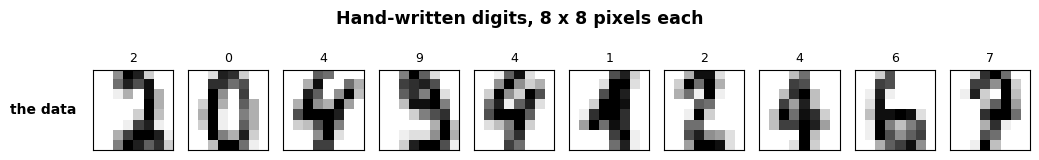

In [2]:
from arti402_figures import (draw_autoencoder_architecture, draw_digit_grid,
                             draw_latent_space, draw_bottleneck_sweep)

draw_digit_grid([("the data", X_test[:10])], titles=y_test[:10],
                suptitle="Hand-written digits, 8 x 8 pixels each")
plt.show()

# Stage 1 · A network with no labels

## Idea 1 — Predict the input

Every network you have built so far was told the right answer. Lab 6's spiral had class labels;
Lab 8's loss compared predictions against `y`. That is **supervised** learning, and it needs
somebody to label the data.

An autoencoder throws the labels away and sets a stranger goal:

> Take the input. Squeeze it through a layer far too small to hold it. Rebuild the original from
> whatever survived.

The target is the input itself, so the loss is `MSE(output, input)`. No labels anywhere. This is
**unsupervised** learning, and it is why autoencoders matter: unlabelled data is free, labelled data
is expensive.

The trick is entirely in the **bottleneck**.

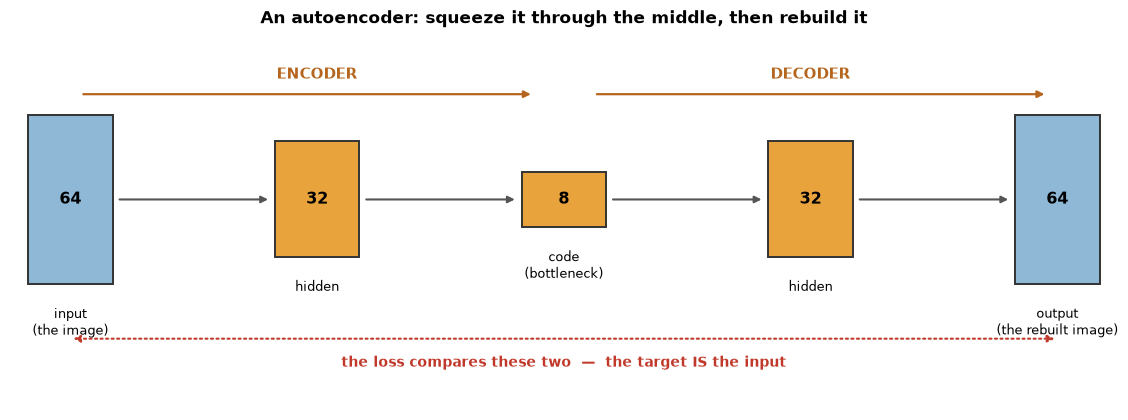

In [5]:
draw_autoencoder_architecture(dims=(64, 32, 8, 32, 64))
plt.show()

Without the narrow middle, the network would learn the identity function — copy the input to the
output, scoring a perfect zero loss and learning nothing. The bottleneck makes that impossible.
64 numbers must pass through 8, so the network has to discover **what in a digit is worth keeping**.

Two names for the two halves:

* the **encoder** maps an image to a short vector — its **code**, or **latent representation**;
* the **decoder** maps a code back to an image.

After training you can throw the decoder away and keep the encoder, which is now a learned
compressor — and that is usually the thing you actually wanted.

### Exercise 1 — build the hourglass

`nn.Sequential` chains layers without writing a `forward` for each one. The `nn.Sigmoid()` at the
end squashes outputs into 0–1, matching our scaled pixels.

In [4]:
class Autoencoder(nn.Module):
    def __init__(self, latent=8, hidden=32):
        super().__init__()
        # TODO 1: encoder = Sequential: Linear(64, hidden) -> ReLU -> Linear(hidden, latent)
        self.encoder = nn.Sequential(
            nn.Linear(64, hidden),
            nn.ReLU(),
            nn.Linear(hidden, latent)
 )
        # TODO 2: decoder = Sequential: Linear(latent, hidden) -> ReLU
        #                               -> Linear(hidden, 64) -> Sigmoid
        self.decoder = nn.Sequential(
            nn.Linear(latent, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 64),
            nn.Sigmoid()
        )
    def forward(self, x):
        # TODO 3: encode, then decode
        return self.decoder(self.encoder(x))


torch.manual_seed(0)
ae = Autoencoder(latent=8)
print(ae)

code_out = ae.encoder(Xte[:5])
recon    = ae(Xte[:5])
print("\n5 images in        :", tuple(Xte[:5].shape))
print("their codes        :", tuple(code_out.shape), "  <- 64 numbers squeezed into 8")
print("rebuilt images     :", tuple(recon.shape))

# --- self-check ---
assert code_out.shape == (5, 8), "the code should have one row per image, 8 numbers wide"
assert recon.shape == Xte[:5].shape, "the output must be the same shape as the input"
assert recon.min() >= 0 and recon.max() <= 1, "Sigmoid should keep outputs in 0-1"

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=8, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=64, bias=True)
    (3): Sigmoid()
  )
)

5 images in        : (5, 64)
their codes        : (5, 8)   <- 64 numbers squeezed into 8
rebuilt images     : (5, 64)


---
# Stage 2 · Training it

## Idea 2 — Your Lab 8 loop, with two words changed

Here is last week's training step beside this week's:

| Lab 8 (classification) | Today (autoencoder) |
|---|---|
| `loss = F.cross_entropy(model(xb), yb)` | `loss = F.mse_loss(model(xb), xb)` |
| target is the **label** | target is the **input** |

`zero_grad → forward → backward → step` is untouched. That is the whole change.

Why **MSE** and not cross-entropy? Because the output is no longer a choice between classes — it
is 64 brightness values, and we want each one close to the original. Cross-entropy answers "which
class?"; MSE answers "how far off?". Choosing the loss to match the question is the skill; the
loop never changes.

### Exercise 2 — train it

In [5]:
def train_autoencoder(model, data, epochs=60, lr=1e-3, batch_size=64, seed=0):
    """Train an autoencoder to reconstruct `data`. Returns a list of mean epoch losses."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # the dataset is (input, target) - and here they are the same tensor
    loader = DataLoader(TensorDataset(data, data), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    history = []

    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, _ in loader:
            # TODO 1: clear the gradients
            optimizer.zero_grad()
            # TODO 2: the loss - mean squared error between the rebuilt image and xb
            loss = F.mse_loss(model(xb), xb)
            # TODO 3: backward
            loss.backward()
            # TODO 4: step
            optimizer.step()
            total += loss.item() * len(xb)
        history.append(total / len(data))

    return history


def reconstruction_error(model, data):
    """Mean squared error over a whole dataset. No gradients."""
    model.eval()
    with torch.no_grad():
        return F.mse_loss(model(data), data).item()


torch.manual_seed(0)
ae = Autoencoder(latent=8)
t0 = time.time()
history = train_autoencoder(ae, Xtr, epochs=60)
print(f"trained in {time.time() - t0:.1f}s")
print(f"epoch  1 loss : {history[0]:.4f}")
print(f"epoch 60 loss : {history[-1]:.4f}")
print(f"\ntest reconstruction error : {reconstruction_error(ae, Xte):.4f}")

# --- self-check ---
assert history[-1] < history[0] / 2, "the loss should fall a long way; check your MSE target"
assert reconstruction_error(ae, Xte) < 0.04, "something is wrong - expect about 0.022"

trained in 5.3s
epoch  1 loss : 0.1782
epoch 60 loss : 0.0216

test reconstruction error : 0.0219


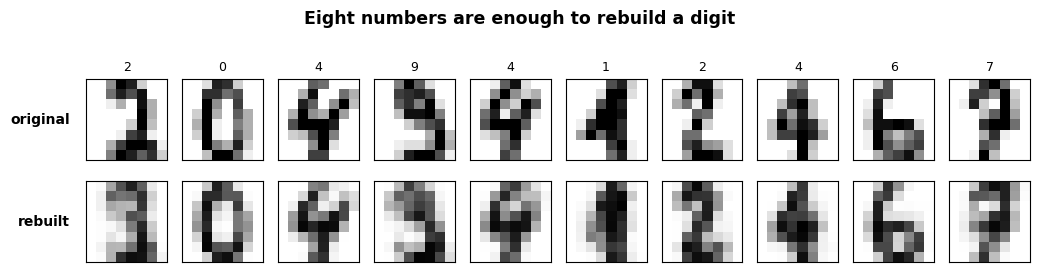

In [6]:
ae.eval()
with torch.no_grad():
    rebuilt = ae(Xte[:10]).numpy()

draw_digit_grid([("original", X_test[:10]), ("rebuilt", rebuilt)],
                titles=y_test[:10],
                suptitle="Eight numbers are enough to rebuild a digit")
plt.show()

Look carefully at the bottom row. The digits are blurrier, and some strokes have thinned — but
every one is still readable. **Those images were reconstructed from 8 numbers each.** The network
was never told what a digit is; it worked out what to keep purely from the pressure of the
bottleneck.

### Checkpoint 1

1. We used `F.mse_loss(model(xb), xb)`. What would happen if the second argument were `yb` — and
   what would the network then be?

   yb is the same as xb, so nothing would change. If yb contained real class labels, the task would become supervised learning. We would need to change the model and loss function to perform classification. 

2. An autoencoder with a 64-neuron bottleneck and no other change could reach a loss of exactly
   zero. How, and why is that useless?

   A network with enough capacity could learn to copy the input directly to the output. This would give zero reconstruction error, but it would not learn useful compression.
   Note: In our architecture, changing only the bottleneck to 64 does not guarantee zero loss because the hidden layers still contain 32 neurons.

3. Autoencoders are called unsupervised, yet the training loop still has a target and a loss.
   Explain why the label "unsupervised" is still fair.

   Because autoencoders do not need class labels. They use the input itself as the target and learn patterns from the data.


---
# Stage 3 · How tight can the bottleneck get?

## Idea 3 — The compression dial

The code size is a dial between two extremes. Wide enough and the network copies its input,
learning nothing. One neuron and nothing survives. Somewhere between is the interesting part.

### Exercise 3 — sweep it

Train one autoencoder per code size and record the error. Each run takes about two seconds.

In [9]:
sizes = [2, 4, 8, 16, 32]
train_mse, test_mse = [], []

for latent in sizes:
    torch.manual_seed(0)
    model = Autoencoder(latent=latent)
    # TODO 1: train it for 60 epochs with train_autoencoder
    train_autoencoder(model, Xtr, epochs=60)
    # TODO 2: append the reconstruction error on Xtr to train_mse,
    #         and on Xte to test_mse
    train_mse.append(reconstruction_error(model, Xtr))
    test_mse.append(reconstruction_error(model, Xte))
    print(f"latent {latent:2d}  train {train_mse[-1]:.4f}  test {test_mse[-1]:.4f}")

# how good is "just predict the average image"? A floor to compare against.
average_image = Xtr.mean(dim=0, keepdim=True)
baseline = F.mse_loss(average_image.expand_as(Xte), Xte).item()
print(f"\npredicting the average image : {baseline:.4f}")

# --- self-check ---
assert len(test_mse) == 5, "one error per code size"
assert test_mse[0] > test_mse[-1], "a wider code should rebuild better"

latent  2  train 0.0467  test 0.0479
latent  4  train 0.0346  test 0.0368
latent  8  train 0.0213  test 0.0219
latent 16  train 0.0193  test 0.0203
latent 32  train 0.0179  test 0.0190

predicting the average image : 0.0740


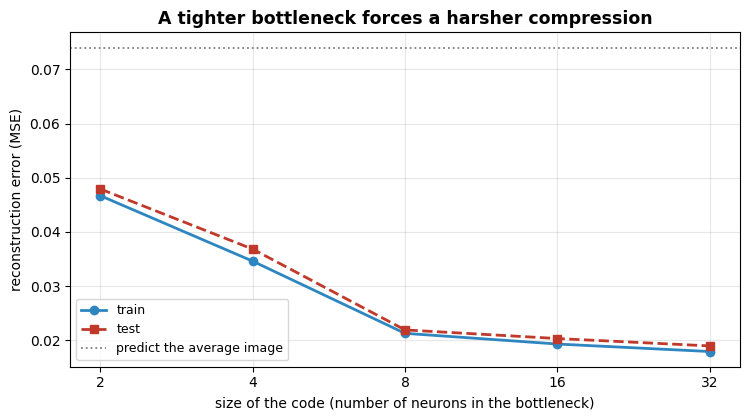

In [10]:
draw_bottleneck_sweep(sizes, train_mse, test_mse, baseline=baseline)
plt.show()

| code size | compression | test MSE |
|---|---|---|
| 2 | 32× | 0.0479 |
| 4 | 16× | 0.0368 |
| 8 | 8× | 0.0219 |
| 16 | 4× | 0.0203 |
| 32 | 2× | 0.0190 |

Notice where the curve flattens. Going from 2 to 8 buys a great deal; going from 8 to 32 buys
very little. There is a point past which extra capacity has nothing left to learn — the digits
simply do not contain that much information.

> **Where is the overfitting?** Train and test errors sit almost on top of each other, unlike every
> previous lab. With 1347 training images and under 5,000 parameters there is nothing to memorise.
> This is a reminder that overfitting is a *relationship* between model size and data size, not a
> property of a model.

## Idea 4 — An old idea you may already know

If you have met **principal component analysis**, an autoencoder with no activation functions is
almost exactly PCA — both find the best linear subspace for reconstruction. The ReLUs are what
make the difference, by letting the code bend.

Running PCA on this same data for comparison gives:

| code size | autoencoder | PCA |
|---|---|---|
| 2 | 0.048 | 0.053 |
| 8 | 0.022 | 0.025 |
| 16 | 0.020 | **0.012** |
| 32 | 0.019 | **0.003** |

The autoencoder wins where the bottleneck is **tight**, which is where the nonlinearity earns its
keep. PCA wins once the code is roomy, because with enough dimensions the optimal linear answer is
already very good — and PCA finds it exactly, in one step, with no training. A deep network is not
automatically the right tool.

---
# Stage 4 · What is inside the code?

## Idea 5 — The encoder is the prize

Train the autoencoder, discard the decoder, keep the encoder: you now have a function that turns
a 64-pixel image into 8 meaningful numbers, learned **without a single label**. That is
**representation learning**, and it is the reason this architecture matters far beyond image
compression.

The test of a representation is whether other things can use it. Let us look at it, then measure it.

### Exercise 4 — look at a 2-D code

codes: (450, 2)  <- two numbers per image


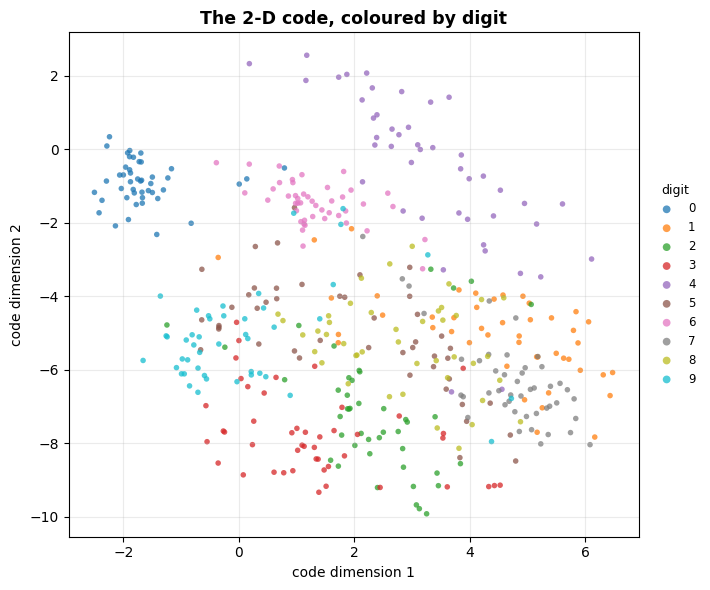

In [11]:
torch.manual_seed(0)
ae2 = Autoencoder(latent=2)
train_autoencoder(ae2, Xtr, epochs=60)

ae2.eval()
with torch.no_grad():
    # TODO: run the ENCODER only on Xte, and convert to NumPy with .numpy()
    Z = ae2.encoder(Xte).numpy()

print("codes:", Z.shape, " <- two numbers per image")
draw_latent_space(Z, y_test)
plt.show()

# --- self-check ---
assert Z.shape == (450, 2), "one 2-number code per test image"

Nobody told it about digits. The colours come from labels we never used in training, yet some
classes have landed in their own regions — the zeros in particular — while others are piled on top
of each other.

That is what a two-number summary of a digit looks like: **real structure, not enough of it.**

### Exercise 5 — measure the representation

A picture is suggestive; a number is evidence. Fit a plain logistic regression on the codes and see
how much class information survived the squeeze.

In [12]:
from sklearn.linear_model import LogisticRegression


def codes_of(model, data):
    model.eval()
    with torch.no_grad():
        return model.encoder(data).numpy()


scores = {}
for latent in [2, 8]:
    torch.manual_seed(0)
    model = Autoencoder(latent=latent)
    train_autoencoder(model, Xtr, epochs=60)
    # TODO 1: get the codes for Xtr and for Xte using codes_of
    Ztr = codes_of(model, Xtr)
    Zte = codes_of(model, Xte)
    clf = LogisticRegression(max_iter=2000).fit(Ztr, y_train)
    scores[f"{latent}-number code"] = clf.score(Zte, y_test)

# TODO 2: the same classifier on the raw 64 pixels, for comparison
raw = LogisticRegression(max_iter=2000).fit(X_train, y_train)
scores["all 64 pixels"] = raw.score(X_test, y_test)

for name, s in scores.items():
    print(f"{name:18} test accuracy {s:.3f}")

# --- self-check ---
assert scores["8-number code"] > scores["2-number code"], "8 numbers should carry more"

2-number code      test accuracy 0.622
8-number code      test accuracy 0.924
all 64 pixels      test accuracy 0.969


Read that table slowly. **Eight unsupervised numbers get you close to all sixty-four pixels** — the
encoder threw away 87% of the data and kept almost everything that mattered for telling digits
apart. Two numbers do not, which is exactly what the scatter plot showed.

This is the practical use of autoencoders in industry: train on a mountain of unlabelled data,
then fit a small supervised model on top of the codes using the few hundred labels you can afford.

### Checkpoint 2

1. The autoencoder never saw `y_train`. How, then, did its codes end up useful for classifying?

   The autoencoder learned useful patterns and features from the images. These features help the classifier recognize different digits even without using labels during autoencoder training.

2. You have 50,000 unlabelled images and 200 labelled ones. Describe how you would use an
   autoencoder, and say which part you would keep.

   First, I would train an autoencoder using the 50,000 unlabelled images. Then, I would keep the encoder and use it to extract features. Finally, I would train a classifier using the 200 labelled images.


3. The 2-D picture put several digits on top of one another. Name one pair you would expect to
   overlap, and say why in terms of the pixels.

   I would expect digits 1 and 7 to overlap because they have similar lines and pixel patterns. With only two features, the encoder may not keep enough information to separate them.

---
# Stage 5 · Denoising

## Idea 6 — Break the input on purpose

A **denoising autoencoder** changes one thing: corrupt the input, but keep the target clean.

```python
noisy = torch.clamp(xb + 0.5 * torch.randn_like(xb), 0, 1)
loss  = F.mse_loss(model(noisy), xb)         # input damaged, target not
```

Now copying is not just hard, it is *wrong* — reproducing the noise would be penalised. The
network must learn what a digit looks like well enough to put back what was removed. This is the
same instinct as Lab 6's dropout: make the task harder on purpose and a better solution comes out.

### Exercise 6 — train one

In [13]:
def train_denoising(model, data, noise=0.5, epochs=60, lr=1e-3, batch_size=64, seed=0):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(data, data), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    for epoch in range(epochs):
        model.train()
        for xb, _ in loader:
            # TODO 1: make `noisy` - xb plus noise * random normal, clamped to 0-1
            noisy = torch.clamp(
                xb + noise * torch.randn_like(xb),
                0, 1
            )
            optimizer.zero_grad()
            # TODO 2: the loss - compare the model's output ON THE NOISY INPUT
            #         against the CLEAN xb
            loss = F.mse_loss(model(noisy), xb)
            loss.backward()
            optimizer.step()
    return model


torch.manual_seed(0)
plain = Autoencoder(latent=8); train_autoencoder(plain, Xtr, epochs=60)
torch.manual_seed(0)
denoiser = Autoencoder(latent=8); train_denoising(denoiser, Xtr, noise=0.5, epochs=60)

torch.manual_seed(7)
Xte_noisy = torch.clamp(Xte + 0.5 * torch.randn_like(Xte), 0, 1)


def mse_against_clean(model, inputs):
    model.eval()
    with torch.no_grad():
        return F.mse_loss(model(inputs), Xte).item()


print(f"{'':24}{'clean input':>13}{'noisy input':>14}")
print(f"{'plain autoencoder':24}{mse_against_clean(plain, Xte):13.4f}"
      f"{mse_against_clean(plain, Xte_noisy):14.4f}")
print(f"{'denoising autoencoder':24}{mse_against_clean(denoiser, Xte):13.4f}"
      f"{mse_against_clean(denoiser, Xte_noisy):14.4f}")
print(f"{'do nothing at all':24}{'-':>13}{F.mse_loss(Xte_noisy, Xte).item():14.4f}")

# --- self-check ---
assert mse_against_clean(denoiser, Xte_noisy) < mse_against_clean(plain, Xte_noisy), \
    "the denoiser should handle noise better - is your target the CLEAN xb?"

                          clean input   noisy input
plain autoencoder              0.0219        0.0534
denoising autoencoder          0.0315        0.0436
do nothing at all                   -        0.1157


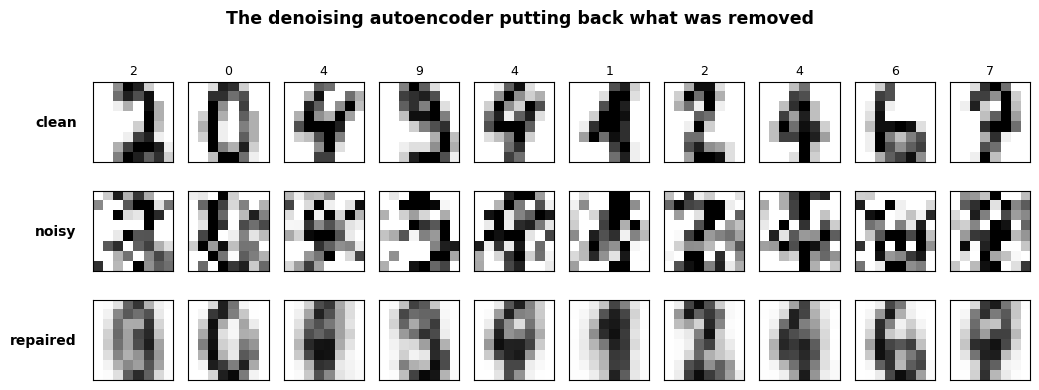

In [14]:
denoiser.eval()
with torch.no_grad():
    cleaned = denoiser(Xte_noisy[:10]).numpy()

draw_digit_grid([("clean", X_test[:10]),
                 ("noisy", Xte_noisy[:10].numpy()),
                 ("repaired", cleaned)],
                titles=y_test[:10],
                suptitle="The denoising autoencoder putting back what was removed")
plt.show()

Two things in that table, and the second one matters more.

The denoiser is clearly better on noisy input. It is also **worse on clean input** than the plain
autoencoder. You did not get robustness for free — you traded some reconstruction accuracy for it,
exactly as dropout traded training accuracy for a smaller gap in Lab 6. Every regularizer is a
trade, and a lab that only showed you the winning column would be lying to you.

---

## What you did today

The first architecture in this course whose goal was not classification.

| | |
|---|---|
| **the shape** | encoder → bottleneck → decoder, trained on `MSE(output, input)` |
| **the trick** | a code too small to hold the input forces the network to choose what matters |
| **the prize** | the encoder — a compressor learned from unlabelled data |
| **denoising** | corrupt the input, keep the target clean, get robustness for a small cost |
| **anomaly detection** | train on normal, alarm on whatever rebuilds badly |

And the loop never changed. `zero_grad → forward → backward → step`, with a different loss and a
different target. That is now three architectures — dense, recurrent, autoencoder — through the
same four lines.

### A gap worth naming

The decoder can turn a code into an image. So could you *invent* a code — pick two numbers at
random, decode them, and get a new digit? Try it and you will mostly get smudges, because nothing
in the training forced the space between the codes to mean anything.

Fixing that is the whole idea of the **variational** autoencoder, which is Lab 11.


### Before next week

* Restart the kernel and run everything top to bottom. Every assertion should pass.
* Spend ten minutes in the [Embedding Projector](https://projector.tensorflow.org/). Load MNIST,
  and look at the same thing you plotted today with far more data behind it.

**End of notebook**